# Column-height probes and interventions (base model)

In [1]:
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import tqdm
from einops import rearrange
from jaxtyping import Float

from connect4.analysis import load_model, board_labels
from connect4.game import COLS, ROWS
from connect4.generate import load_games
from connect4.tokenizer import encode
from connect4.path import ROOT_DIR

## Config

In [3]:
MODEL_PATH = ROOT_DIR / "runs" / "base" / "model.pt"
PROBE_DATA_PATH = ROOT_DIR / "data" / "probe_100k"
PROBES_PATH = ROOT_DIR / "runs" / "base" / "height_probes.pt"  # probes + per-layer mean/std
FIG_DIR = ROOT_DIR / "figures"

N_GAMES = 5000
TRAIN_FRAC = 0.8          # split by game, not by position
BATCH_SIZE = 512
PROBE_LR = 1e-2
PROBE_EPOCHS = 50
RETRAIN_PROBES = False    # True: train even if PROBES_PATH exists (takes ~3 min)

N_HEIGHTS = ROWS + 1      # a column holds 0-6 pieces
TARGET_COL = 3
# Push size as a fraction of the activation's own size, so every layer gets the same range.
RELATIVE_PUSHES = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2]

FIG_DIR.mkdir(exist_ok=True)
# Saved figures get a transparent background so they sit on any page color.
plt.rcParams["savefig.transparent"] = True
plt.rcParams["legend.framealpha"] = 0
device = torch.device("mps" if torch.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)

## Model and data

In [4]:
model, train_cfg = load_model(MODEL_PATH, device)
games = load_games(PROBE_DATA_PATH)[:N_GAMES]
labels = board_labels(games)
tokens = torch.from_numpy(encode(games, train_cfg["end_token"])[:, :-1]).long().to(device)  # (games, 43)

layer_names = ["embed", *[f"blocks_{i}" for i in range(model.cfg.n_layers)]]

# Sanity check against stale notebook state: at BOS every column should get ~1/7.
with torch.no_grad():
    bos_probs = F.softmax(model(tokens[:1, :1]), dim=-1)[0, 0, :COLS]
assert torch.allclose(bos_probs, torch.full_like(bos_probs, 1 / COLS), atol=0.01), bos_probs
tokens.shape

torch.Size([5000, 43])

## Activations

In [5]:
def extract_activations(model, tokens, batch_size=BATCH_SIZE) -> dict[str, torch.Tensor]:
    """Residual stream at every layer: name -> (games, positions, d_model), on the CPU."""
    saved = {name: [] for name in layer_names}

    def save_output(name):
        def hook(module, inputs, output):
            saved[name].append(output.detach().cpu())
        return hook

    def save_input(name):
        def hook(module, inputs):
            saved[name].append(inputs[0].detach().cpu())
        return hook

    # The embeddings aren't a module output, so they're read as the input to block 0.
    handles = [model.blocks[0].register_forward_pre_hook(save_input("embed"))]
    for i, block in enumerate(model.blocks):
        handles.append(block.register_forward_hook(save_output(f"blocks_{i}")))
    try:
        with torch.no_grad():
            for b in range(0, len(tokens), batch_size):
                model(tokens[b : b + batch_size])
    finally:
        for handle in handles:
            handle.remove()
    return {name: torch.cat(chunks) for name, chunks in saved.items()}


activations = extract_activations(model, tokens)

# Split by game, then keep only positions inside the game (mask flattens games x positions into rows).
train_n = int(N_GAMES * TRAIN_FRAC)
valid = torch.from_numpy(labels.valid)
heights = torch.from_numpy(labels.heights).long()

train_acts = {name: acts[:train_n][valid[:train_n]] for name, acts in activations.items()}
val_acts = {name: acts[train_n:][valid[train_n:]] for name, acts in activations.items()}
train_heights = heights[:train_n][valid[:train_n]]  # (rows, 7 columns)
val_heights = heights[train_n:][valid[train_n:]]

train_acts["embed"].shape, val_acts["embed"].shape

(torch.Size([90525, 512]), torch.Size([22918, 512]))

## Probes

In [6]:
def probe_logits(probe, x):
    # The 49 outputs are height-major: index = height * COLS + col.
    return rearrange(probe(x), "n (height col) -> n height col", height=N_HEIGHTS)


def train_probe(train_x, train_y, *, batch_size=BATCH_SIZE, lr=PROBE_LR, epochs=PROBE_EPOCHS):
    probe = nn.Linear(train_x.size(1), N_HEIGHTS * COLS).to(device)
    optimizer = optim.AdamW(probe.parameters(), lr=lr)
    train_x, train_y = train_x.to(device), train_y.to(device)
    for _ in tqdm.trange(epochs, leave=False):
        order = torch.randperm(len(train_x), device=device)
        for b in range(0, len(train_x), batch_size):
            idx = order[b : b + batch_size]
            loss = F.cross_entropy(probe_logits(probe, train_x[idx]), train_y[idx])  # classes = dim 1 = height
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return probe


@torch.no_grad()
def evaluate_probe(probe, x, y) -> tuple[float, torch.Tensor]:
    """Overall accuracy, and accuracy for each true height (7,)."""
    x, y = x.to(device), y.to(device)
    pred = probe_logits(probe, x).argmax(dim=1)  # (rows, cols)
    per_height = torch.stack([(pred[y == k] == k).float().mean() for k in range(N_HEIGHTS)])
    return (pred == y).float().mean().item(), per_height.cpu()


def standardize(x, name):
    mean, std = (t.to(x.device) for t in norms[name])
    return (x - mean) / (std + 1e-6)

In [7]:
probes = nn.ModuleDict({name: nn.Linear(model.cfg.d_model, N_HEIGHTS * COLS) for name in layer_names}).to(device)

if PROBES_PATH.exists() and not RETRAIN_PROBES:
    saved = torch.load(PROBES_PATH, map_location=device, weights_only=True)
    probes.load_state_dict(saved["probes"])
    norms = saved["norms"]
    print(f"loaded probes from {PROBES_PATH}")
else:
    # mean/std come from the training rows only, and are reused for validation and interventions.
    norms = {name: (train_acts[name].mean(0), train_acts[name].std(0)) for name in layer_names}
    for name in layer_names:
        print(name)
        probes[name] = train_probe(standardize(train_acts[name], name), train_heights)
    torch.save({"probes": probes.state_dict(), "norms": norms}, PROBES_PATH)
    print(f"saved probes to {PROBES_PATH}")

loaded probes from /Users/alisher/Developer/connect-4/runs/base/height_probes.pt


In [8]:
accs, height_accs = {}, {}
for name in layer_names:
    accs[name], height_accs[name] = evaluate_probe(probes[name], standardize(val_acts[name], name), val_heights)

# Baseline: always guess the most common height for each column.
baseline = (val_heights == train_heights.mode(0).values).float().mean().item()

print(f"{'layer':9s} {'overall':>8s}  " + " ".join(f"h={k:<4d}" for k in range(N_HEIGHTS)))
for name in layer_names:
    print(f"{name:9s} {accs[name]:8.2%}  " + " ".join(f"{a:6.1%}" for a in height_accs[name].tolist()))
print(f"\nbaseline (most common height per column): {baseline:.1%}")

layer      overall  h=0    h=1    h=2    h=3    h=4    h=5    h=6   
embed       41.12%   69.7%  39.3%  28.6%  23.8%  14.1%   6.9%  38.6%
blocks_0    99.48%  100.0%  99.7%  99.7%  98.5%  98.7%  98.1%  99.3%
blocks_1    99.05%   99.9%  99.6%  99.1%  98.2%  95.7%  97.5% 100.0%
blocks_2    98.62%   99.9%  99.8%  98.3%  97.3%  93.2%  97.0% 100.0%
blocks_3    96.85%   99.7%  99.3%  94.5%  93.4%  90.5%  91.3% 100.0%
blocks_4    94.07%   99.3%  96.8%  90.0%  86.7%  85.3%  90.8% 100.0%
blocks_5    94.43%   99.4%  97.3%  90.0%  88.3%  88.0%  86.1% 100.0%
blocks_6    95.09%   99.5%  97.7%  91.1%  90.1%  86.5%  91.4%  99.9%
blocks_7    95.70%   99.5%  98.0%  93.4%  91.5%  87.3%  88.6%  99.9%

baseline (most common height per column): 29.5%


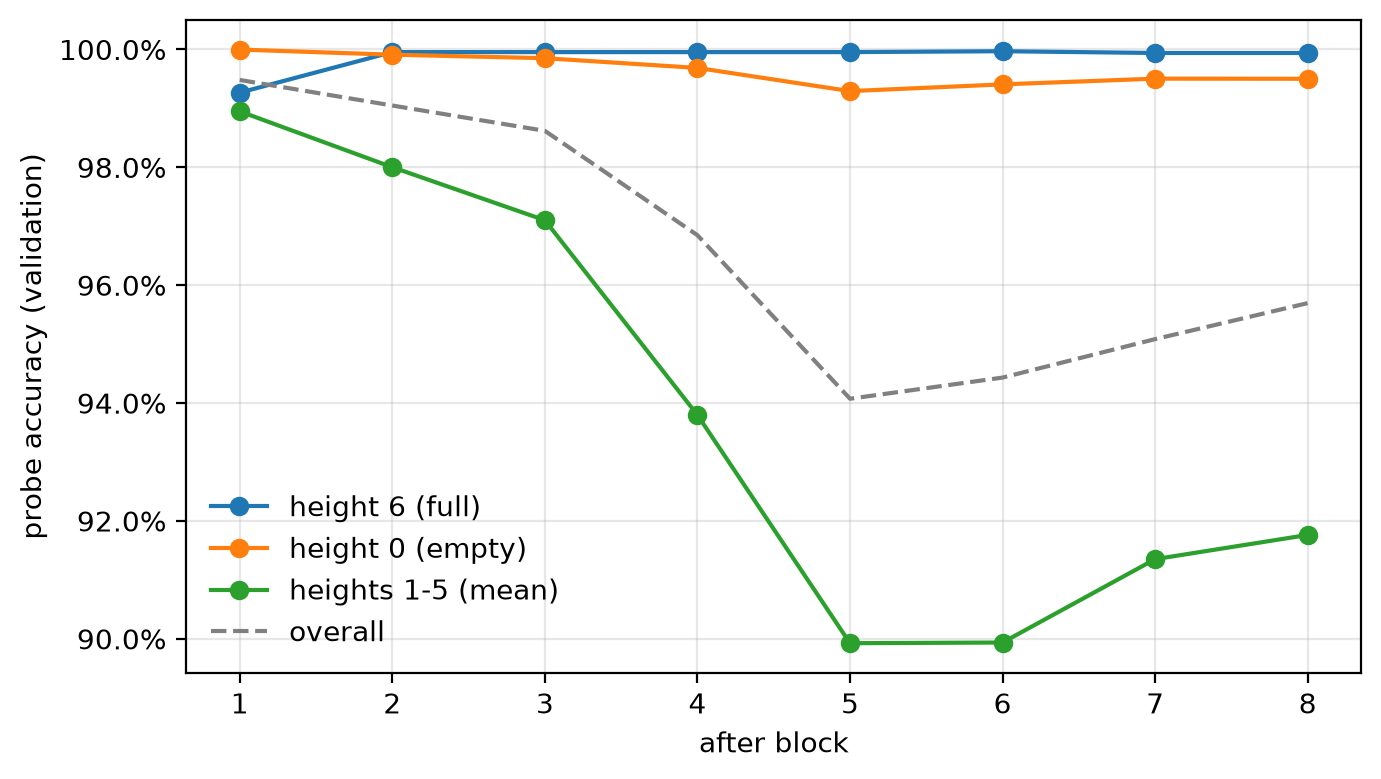

In [9]:
blocks = layer_names[1:]  # the embedding layer is left out of the plot (see the printed table)
x = range(1, len(blocks) + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, [height_accs[n][6] for n in blocks], marker="o", label="height 6 (full)")
ax.plot(x, [height_accs[n][0] for n in blocks], marker="o", label="height 0 (empty)")
ax.plot(x, [height_accs[n][1:6].mean() for n in blocks], marker="o", label="heights 1-5 (mean)")
ax.plot(x, [accs[n] for n in blocks], ls="--", color="gray", label="overall")
ax.set_xticks(list(x))
ax.set_xlabel("after block")
ax.set_ylabel("probe accuracy (validation)")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "probe_accuracy_by_height.svg", bbox_inches="tight")
fig.savefig(FIG_DIR / "probe_accuracy_by_height.png", dpi=200, bbox_inches="tight")
plt.show()

# Intervention at BOS

Position 0 only ever sees BOS (causal attention), so a single one-token sequence is enough:
every game would give the same result there.

In [10]:
def probe_direction(name, height, col) -> Float[torch.Tensor, "d_model"]:
    w = rearrange(probes[name].weight, "(height col) d -> height col d", height=N_HEIGHTS)
    return w[height, col].detach()


def make_intervention_hook(position: int, vector: Float[torch.Tensor, "d_model"]):
    def hook(module, inputs, output):
        output = output.clone()
        output[:, position, :] += vector
        return output
    return hook


def run_with_push(block_idx, vector, x):
    handle = model.blocks[block_idx].register_forward_hook(make_intervention_hook(0, vector))
    try:
        with torch.no_grad():
            return F.softmax(model(x), dim=-1)
    finally:
        handle.remove()

In [11]:
bos = tokens[:1, :1]
with torch.no_grad():
    _, clean_resid = model(bos, return_resid=True)  # resid[j + 1] = output of block j

gen = torch.Generator(device="cpu").manual_seed(0)
intervention_data = []
for j in range(model.cfg.n_layers):
    direction = probe_direction(f"blocks_{j}", height=ROWS, col=TARGET_COL)  # "TARGET_COL is full"
    random_dir = torch.randn(direction.shape, generator=gen).to(device)
    random_dir = random_dir / random_dir.norm() * direction.norm()
    activation_len = clean_resid[j + 1][0, 0].norm().item()

    for relative_push in RELATIVE_PUSHES:
        alpha = relative_push * activation_len / direction.norm().item()
        for kind, vector in [("probe", direction), ("random", random_dir)]:
            probs = run_with_push(j, vector * alpha, bos)
            intervention_data.append({
                "kind": kind,
                "layer": j,
                "alpha": alpha,
                "relative_push": relative_push,
                "p_target": probs[0, 0, TARGET_COL].item(),
            })
len(intervention_data)

144

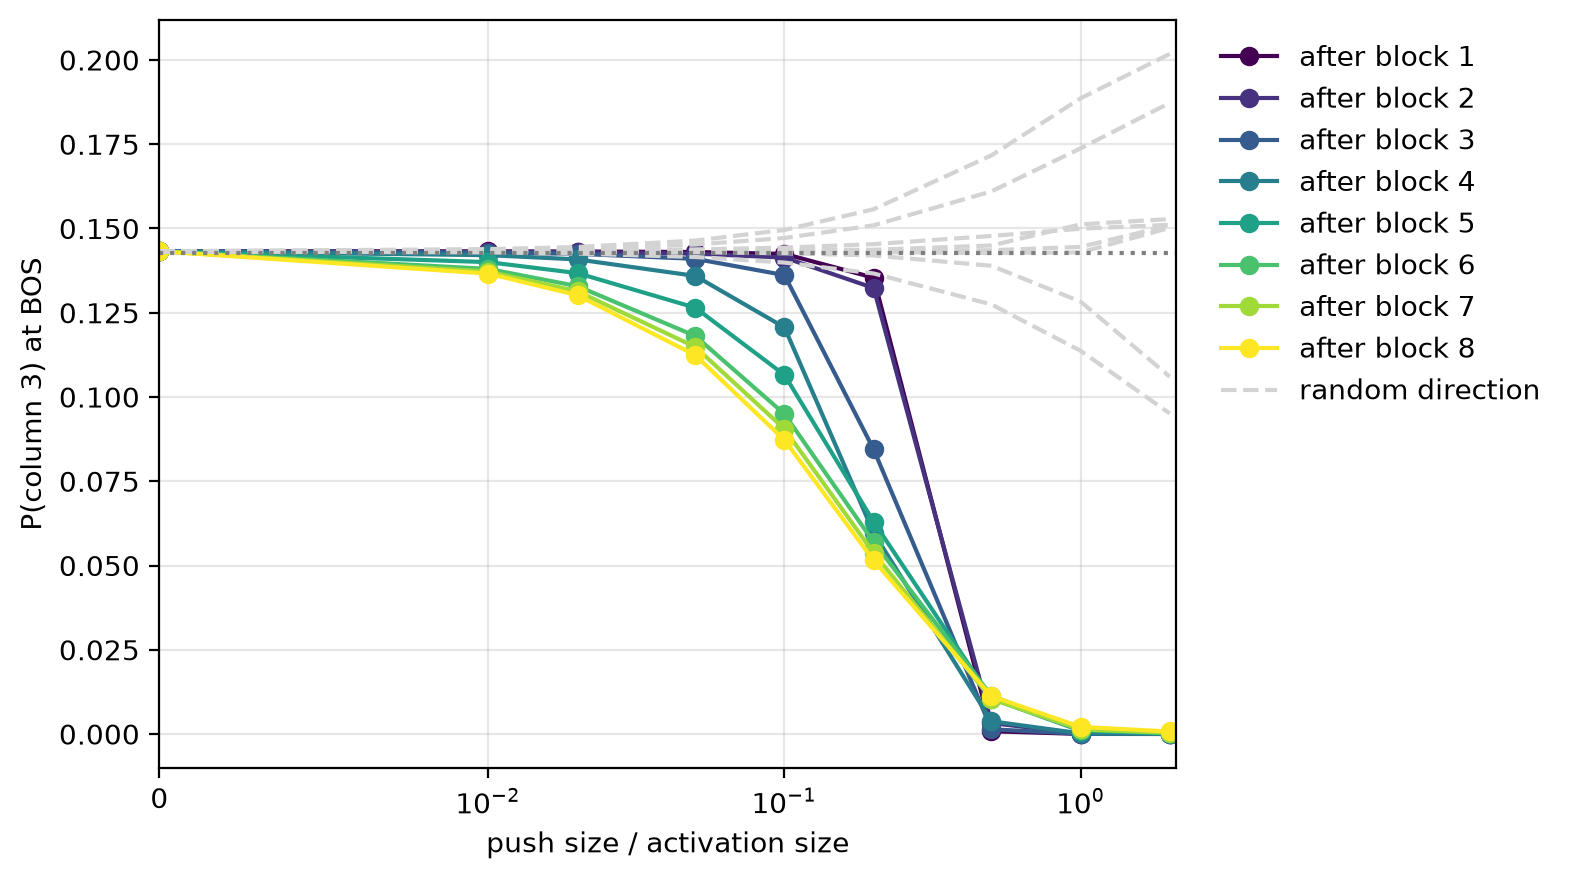

In [12]:
def series(kind, j, key):
    return [r[key] for r in intervention_data if r["kind"] == kind and r["layer"] == j]


fig, ax = plt.subplots(figsize=(8, 4.5))
for j in range(model.cfg.n_layers):
    ax.plot(series("probe", j, "relative_push"), series("probe", j, "p_target"),
            marker="o", color=plt.cm.viridis(j / (model.cfg.n_layers - 1)), label=f"after block {j + 1}")
for j in range(model.cfg.n_layers):
    ax.plot(series("random", j, "relative_push"), series("random", j, "p_target"),
            ls="--", color="lightgray", label="random direction" if j == 0 else None)
ax.axhline(1 / COLS, ls=":", color="gray")
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(left=0)
ax.set_xlabel("push size / activation size")
ax.set_ylabel(f"P(column {TARGET_COL}) at BOS")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "intervention_bos.svg", bbox_inches="tight")
fig.savefig(FIG_DIR / "intervention_bos.png", dpi=200, bbox_inches="tight")
plt.show()

# Intervention at mid-game positions

One position per game, so each edit can't leak into another measurement (edits only affect later positions).
Games come from the validation split, which the probes never trained on.

In [14]:
# A position t qualifies when:
#   - the game isn't over at t: another move follows, so the model's prediction at t is a real next move
#   - TARGET_COL isn't full yet, so there's something to push toward "full"
#   - t > 0: BOS is covered above
val_games = torch.arange(train_n, N_GAMES)
next_move_exists = torch.zeros_like(valid)
next_move_exists[:, :-1] = valid[:, 1:]
eligible = next_move_exists & (heights[:, :, TARGET_COL] < ROWS)
eligible[:, 0] = False
eligible = eligible[val_games]                                   # (val games, positions)

has_any = eligible.any(dim=1)
gen = torch.Generator().manual_seed(0)
t_idx = torch.multinomial(eligible[has_any].float(), 1, generator=gen).squeeze(1)  # one random eligible t per game
game_idx = val_games[has_any]

mid_tokens = tokens[game_idx]                                    # (B, 43): the full games, on `device`
rows = torch.arange(len(game_idx))                               # use with t_idx: x[rows, t_idx]
start_heights = heights[game_idx, t_idx, TARGET_COL]             # column height before the push, for later splits

print(f"{len(game_idx)} games, position t from {t_idx.min()} to {t_idx.max()} (median {t_idx.median()})")
print("starting height of the target column:", torch.bincount(start_heights, minlength=ROWS).tolist())

1000 games, position t from 1 to 33 (median 10)
starting height of the target column: [324, 271, 210, 107, 66, 22]


In [15]:
t_idx.shape, mid_tokens.shape

(torch.Size([1000]), torch.Size([1000, 43]))

In [ ]:
for j in range(model.cfg.n_layers):
    direction = probe_direction(f"blocks_{j}", height=ROWS, col=)